# 06 — Multi-Class Attack Family Categorization
## 10-Class Threat Classifier (Normal + 9 Specific Attack Families)

### Objective:
While Notebooks 01–05 focus on **Binary Intrusion Detection** (NORMAL vs ATTACK), this notebook trains the **Multi-Class Threat Categorization Model** on the **full training dataset (175,341 flows)**.
When a flow is flagged as malicious, this model answers: **What kind of attack is it?**

### 10 Categories Covered:
1. **Normal** (Benign)
2. **Generic** (Protocol & cipher anomalies)
3. **Exploits** (RCE, buffer overflows)
4. **Fuzzers** (Malformed protocol payloads)
5. **DoS** (Volumetric floods)
6. **Reconnaissance** (Port scans & network sweeps)
7. **Analysis** (Vulnerability scans)
8. **Backdoor** (C2 beaconing)
9. **Shellcode** (Injected bytecode execution)
10. **Worms** (Lateral spreading)

In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, StandardScaler, OrdinalEncoder
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay

DATA_DIR = Path('../data/raw')
MODELS_DIR = Path('../models')
MODELS_DIR.mkdir(parents=True, exist_ok=True)

train_df = pd.read_csv(DATA_DIR / 'UNSW_NB15_training-set.csv', low_memory=False)
test_df = pd.read_csv(DATA_DIR / 'UNSW_NB15_testing-set.csv', low_memory=False)

train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()

# Standardize attack_cat labels
train_df['attack_cat'] = train_df['attack_cat'].astype(str).str.strip().replace({'Backdoors': 'Backdoor'})
test_df['attack_cat'] = test_df['attack_cat'].astype(str).str.strip().replace({'Backdoors': 'Backdoor'})

print(f'Training records: {len(train_df):,}')
print(f'Testing records:  {len(test_df):,}')
print('\nTraining distribution across all 10 categories:')
display(train_df['attack_cat'].value_counts())


Training records: 175,341
Testing records:  82,332

Training distribution across all 10 categories:


attack_cat
Normal            56000
Generic           40000
Exploits          33393
Fuzzers           18184
DoS               12264
Reconnaissance    10491
Analysis           2000
Backdoor           1746
Shellcode          1133
Worms               130
Name: count, dtype: int64

### 1. Target Encoding Across All 10 Classes

In [2]:
ATTACK_CATEGORIES = [
    'Normal', 'Generic', 'Exploits', 'Fuzzers', 'DoS',
    'Reconnaissance', 'Analysis', 'Backdoor', 'Shellcode', 'Worms'
]

label_encoder = LabelEncoder()
label_encoder.fit(ATTACK_CATEGORIES)

y_train = label_encoder.transform(train_df['attack_cat'])
y_test = label_encoder.transform(test_df['attack_cat'])

excluded = ['id', 'label', 'attack_cat']
X_train = train_df.drop(columns=excluded)
X_test = test_df.drop(columns=excluded)

categorical_cols = ['proto', 'service', 'state']
numerical_cols = [c for c in X_train.columns if c not in categorical_cols]


### 2. Train Multi-Class XGBoost Classifier on Full Training Set

In [3]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numerical_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        ]), categorical_cols)
    ]
)

classifier = XGBClassifier(
    objective='multi:softprob',
    num_class=len(ATTACK_CATEGORIES),
    n_estimators=150,
    max_depth=6,
    learning_rate=0.10,
    subsample=0.85,
    colsample_bytree=0.85,
    random_state=42,
    n_jobs=-1,
    eval_metric='mlogloss'
)

pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', classifier)
])

print('Training 10-Class Threat Classifier on full 175,341 records...')
pipeline.fit(X_train, y_train)

y_pred = pipeline.predict(X_test)
acc = accuracy_score(y_test, y_pred) * 100
print(f'Test Multi-Class Accuracy on 82,332 held-out flows: {acc:.2f}%')


Training 10-Class Threat Classifier on full 175,341 records...
Test Multi-Class Accuracy on 82,332 held-out flows: 77.07%


### 3. Detailed Evaluation & Confusion Matrix

=== Multi-Class Threat Classification Report (Held-Out Test Set) ===
                precision    recall  f1-score   support

        Normal     0.0651    0.1388    0.0886       677
       Generic     0.0355    0.0840    0.0499       583
      Exploits     0.5433    0.0890    0.1530      4089
       Fuzzers     0.6027    0.8605    0.7089     11132
           DoS     0.3187    0.5942    0.4149      6062
Reconnaissance     0.9958    0.9712    0.9833     18871
      Analysis     0.9677    0.7643    0.8541     37000
      Backdoor     0.9325    0.8101    0.8670      3496
     Shellcode     0.3252    0.8148    0.4649       378
         Worms     0.5926    0.3636    0.4507        44

      accuracy                         0.7707     82332
     macro avg     0.5379    0.5491    0.5035     82332
  weighted avg     0.8373    0.7707    0.7835     82332



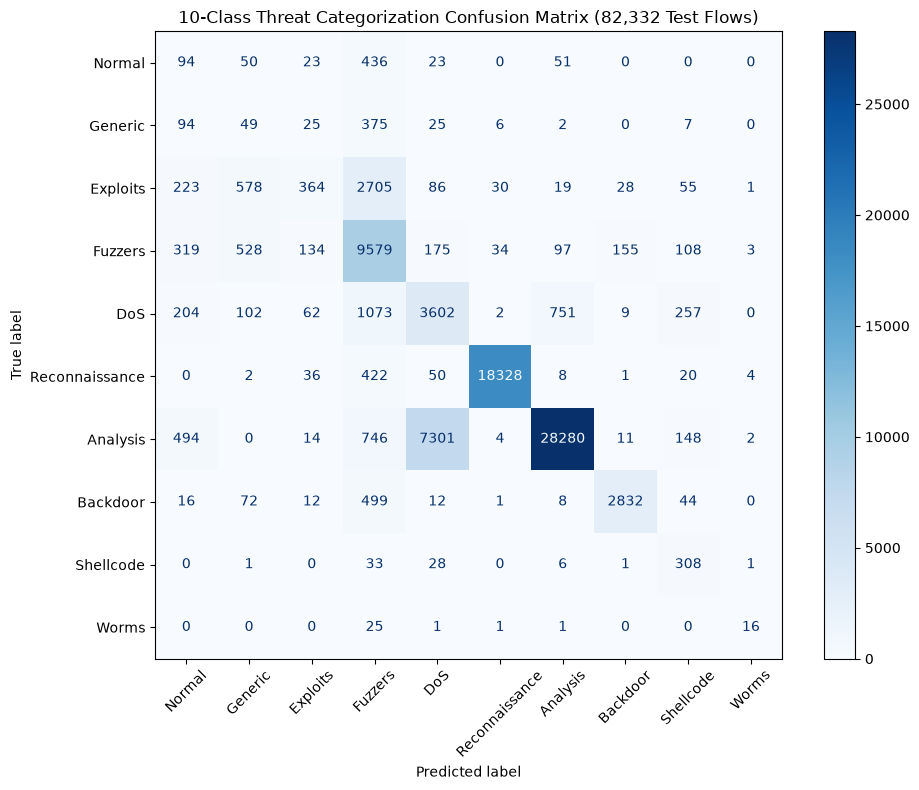

In [4]:
print('=== Multi-Class Threat Classification Report (Held-Out Test Set) ===')
print(classification_report(y_test, y_pred, target_names=ATTACK_CATEGORIES, digits=4))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=ATTACK_CATEGORIES,
    xticks_rotation=45,
    cmap='Blues',
    ax=ax
)
ax.set_title('10-Class Threat Categorization Confusion Matrix (82,332 Test Flows)')
plt.tight_layout()
plt.show()


### 4. Save Multi-Class Model & Label Encoder
Exports multiclass_model.joblib and multiclass_labels.joblib for direct dashboard and API consumption.

In [5]:
model_path = MODELS_DIR / 'multiclass_model.joblib'
labels_path = MODELS_DIR / 'multiclass_labels.joblib'

print('Saving multi-class artifacts...')
joblib.dump(pipeline, model_path, compress=3)
joblib.dump(label_encoder, labels_path)

print(f'[OK] Saved: {model_path} ({model_path.stat().st_size / 1024:.1f} KB)')
print(f'[OK] Saved: {labels_path} ({labels_path.stat().st_size / 1024:.1f} KB)')


Saving multi-class artifacts...
[OK] Saved: ..\models\multiclass_model.joblib (1478.5 KB)
[OK] Saved: ..\models\multiclass_labels.joblib (0.9 KB)
